# **Mini Assignment: Perbandingan Logistic Regression dan Random Forest pada Klasifikasi Kanker Payudara**

**Implementasi Machine Learning Menggunakan Python dan Google Colab**

| | |
|:--|:--|
| Nama | Sinar Lintang Sejati |
| NIM | B1C024035 |
| Program Studi | S1 Biologi Terapan, Fakultas Biologi, Universitas Jenderal Soedirman |

Notebook ini melanjutkan contoh praktikum TM12 (klasifikasi kanker payudara dengan Logistic Regression). Dataset yang digunakan adalah Breast Cancer Wisconsin Dataset dari Scikit-learn (569 sampel, 30 fitur numerik) dengan dua kelas:

*   Malignant (0): Tumor ganas.
*   Benign (1): Tumor jinak.

Perubahan dari contoh praktikum:

1.   Pembagian dataset diubah dari 80:20 menjadi **70% training dan 30% testing**.
2.   Ditambahkan algoritma **Random Forest Classifier** sebagai pembanding Logistic Regression.
3.   Kedua algoritma dibandingkan menggunakan accuracy, precision, recall, F1-score, dan Confusion Matrix.
4.   Dibuat analisis algoritma mana yang lebih baik serta penjelasan mengapa accuracy saja tidak cukup.

# **Step 1: Import Libraries**

Mengimpor library untuk pengolahan data, visualisasi, pembangunan model, dan evaluasi. Dibandingkan contoh praktikum, ditambahkan `RandomForestClassifier` serta fungsi `precision_score`, `recall_score`, dan `f1_score`.

In [1]:
# Library untuk pengolahan data numerik
import os
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset, normalisasi data, dan cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    make_scorer
)

# Folder untuk menyimpan gambar hasil
os.makedirs("results", exist_ok=True)

print("Semua librari berhasil dimasukkan")

Semua librari berhasil dimasukkan


# **Step 2: Load Dataset**

Dataset dimuat dengan `load_breast_cancer()` lalu dikonversi menjadi DataFrame Pandas.

In [2]:
# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

Penjelasan:

*   `X` menyimpan 30 fitur numerik karakteristik sel tumor.
*   `y` menyimpan label kelas: 0 = malignant, 1 = benign.

# **Step 3: Exploratory Data Analysis (EDA)**

Pemeriksaan singkat kualitas data dan distribusi kelas sebelum pemodelan.

Missing Values: 0

Class Distribution:
0    212
1    357
Name: count, dtype: int64

Proporsi malignant: 37.3%
Proporsi benign   : 62.7%


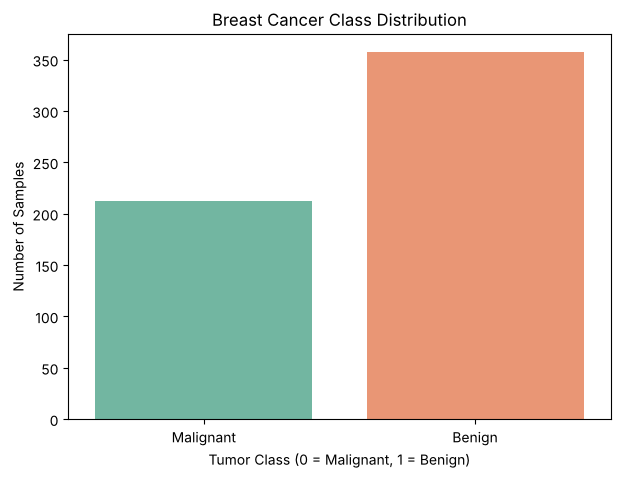

In [3]:
# Memeriksa jumlah missing values
print("Missing Values:", X.isnull().sum().sum())

# Menghitung jumlah sampel pada setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

print("\nClass Distribution:")
print(class_counts)
print("\nProporsi malignant: {:.1%}".format(class_counts[0] / len(y)))
print("Proporsi benign   : {:.1%}".format(class_counts[1] / len(y)))

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

Penjelasan:

Tidak ada nilai yang hilang. Kelas benign (357 sampel, 62,7%) lebih banyak daripada malignant (212 sampel, 37,3%). Ketidakseimbangan ini sedang, tetapi cukup penting untuk diperhatikan saat mengevaluasi model (lihat Step 9).

# **Step 4: Dataset Splitting (70% Training dan 30% Testing)**

Dataset dibagi menjadi:

*   70% Training Data (untuk melatih model).
*   30% Testing Data (untuk menguji model).

Pembagian yang **sama** dipakai untuk kedua algoritma agar perbandingan adil.

In [4]:
# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0], "({:.0%})".format(X_train.shape[0] / len(X)))
print("Testing Samples :", X_test.shape[0], "({:.0%})".format(X_test.shape[0] / len(X)))

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nMalignant pada data uji:", (y_test == 0).sum())
print("Benign pada data uji   :", (y_test == 1).sum())

Training Samples: 398 (70%)
Testing Samples : 171 (30%)

Training Features: (398, 30)
Testing Features: (171, 30)

Malignant pada data uji: 64
Benign pada data uji   : 107


Penjelasan parameter:

*   `test_size=0.3`: 30% data digunakan untuk pengujian (diubah dari 0.2 pada contoh praktikum).
*   `random_state=42`: menjaga konsistensi pembagian data.
*   `stratify=y`: mempertahankan proporsi kelas pada training dan testing.

# **Step 5: Membangun Model**

Dua model dibangun dan dilatih pada data training yang sama:

**1. Logistic Regression** (dari contoh praktikum). Memakai `StandardScaler` di dalam Pipeline karena model linear sensitif terhadap skala fitur. Scaler hanya mempelajari parameter dari data training sehingga tidak terjadi data leakage.

**2. Random Forest Classifier.** Gabungan 100 pohon keputusan (`n_estimators=100`) yang hasil prediksinya digabung melalui voting. Model berbasis pohon tidak bergantung pada skala fitur sehingga tidak memerlukan `StandardScaler`.

In [5]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
}

# Melatih kedua model menggunakan data training yang sama
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "- Training Completed!")

Logistic Regression - Training Completed!
Random Forest - Training Completed!


# **Step 6: Model Prediction**

Kedua model digunakan untuk memprediksi data testing.

In [6]:
preds = {}
probas = {}

for name, model in models.items():
    preds[name] = model.predict(X_test)
    probas[name] = model.predict_proba(X_test)[:, 1]

    print(name)
    print("Predicted:", preds[name][:30], "...")
    print("Actual   :", y_test[:30], "...\n")

Logistic Regression
Predicted: [0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0] ...
Actual   : [0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0] ...

Random Forest
Predicted: [0 1 1 0 1 0 1 0 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 0 0 1 1 1 0 0] ...
Actual   : [0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0] ...



Penjelasan:

`predict()` menghasilkan kelas prediksi, sedangkan `predict_proba()` menghasilkan probabilitas kelas benign yang dipakai untuk menghitung ROC-AUC.

# **Step 7: Model Evaluation**

Metrik yang digunakan: Accuracy, Precision, Recall, F1-Score, dan ROC-AUC.

Pada praktikum, kelas positif default adalah kelas 1 (Benign). Pada klasifikasi kanker, kelas yang paling penting dideteksi adalah **malignant (0)**, sehingga pada perbandingan ini **precision, recall, dan F1-score dihitung dengan malignant sebagai kelas positif** (`pos_label=0`). Dengan begitu:

*   **Recall** = dari seluruh tumor ganas yang sebenarnya, berapa yang berhasil terdeteksi.
*   **Precision** = dari seluruh prediksi ganas, berapa yang benar-benar ganas.

$$
Accuracy = \frac{TP+TN}{TP+TN+FP+FN} \quad
Precision = \frac{TP}{TP+FP} \quad
Recall = \frac{TP}{TP+FN} \quad
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

In [7]:
# Classification report lengkap untuk kedua kelas
for name in models:
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, preds[name], target_names=data.target_names))

Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

Random Forest
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



In [8]:
# Tabel perbandingan metrik (malignant sebagai kelas positif)
rows = []
for name in models:
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision (malignant)": precision_score(y_test, preds[name], pos_label=0),
        "Recall (malignant)": recall_score(y_test, preds[name], pos_label=0),
        "F1-score (malignant)": f1_score(y_test, preds[name], pos_label=0),
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,Accuracy,Precision (malignant),Recall (malignant),F1-score (malignant),ROC-AUC
Model,,,,,
Logistic Regression,0.9883,0.9844,0.9844,0.9844,0.9981
Random Forest,0.9357,0.9206,0.9062,0.9134,0.9913


**Visualisasi perbandingan metrik**

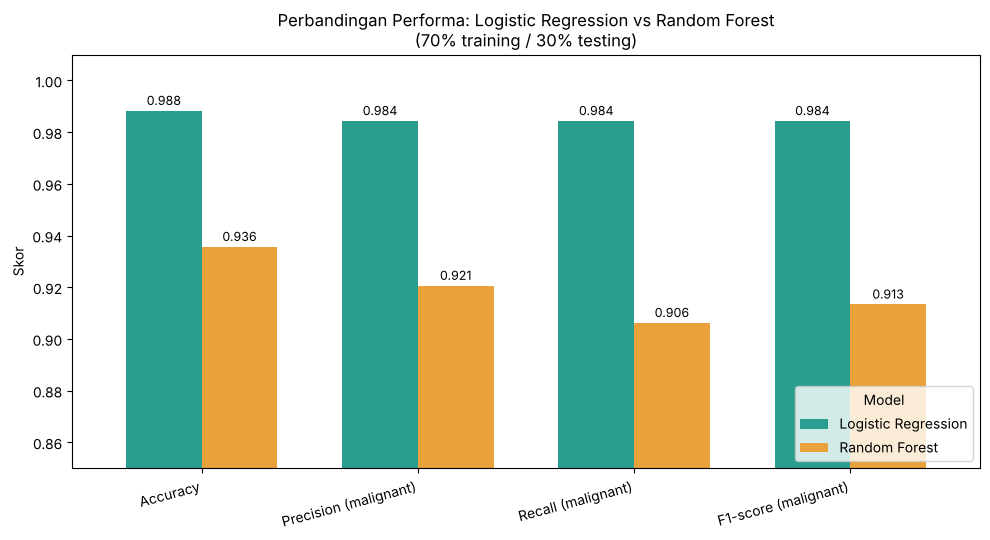

In [9]:
metrics = ["Accuracy", "Precision (malignant)", "Recall (malignant)", "F1-score (malignant)"]

ax = results[metrics].T.plot(kind="bar", figsize=(10, 5.5), width=0.7, color=["#2a9d8f", "#e9a23b"])
ax.set_title("Perbandingan Performa: Logistic Regression vs Random Forest\n(70% training / 30% testing)")
ax.set_ylabel("Skor")
ax.set_ylim(0.85, 1.01)
plt.xticks(rotation=15, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=9, padding=2)
plt.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.savefig("results/evaluation_results.png", dpi=150, bbox_inches="tight")
plt.show()

# **Step 8: Confusion Matrix Kedua Algoritma**

Pada Confusion Matrix berikut (baris = kelas sebenarnya, kolom = prediksi), sel di baris *malignant* dan kolom *benign* adalah **False Negative**: tumor ganas yang salah diprediksi jinak. Kesalahan inilah yang paling berbahaya dalam konteks klinis.

Logistic Regression: False Negative (malignant -> benign) = 1, False Positive (benign -> malignant) = 1
Random Forest: False Negative (malignant -> benign) = 6, False Positive (benign -> malignant) = 5


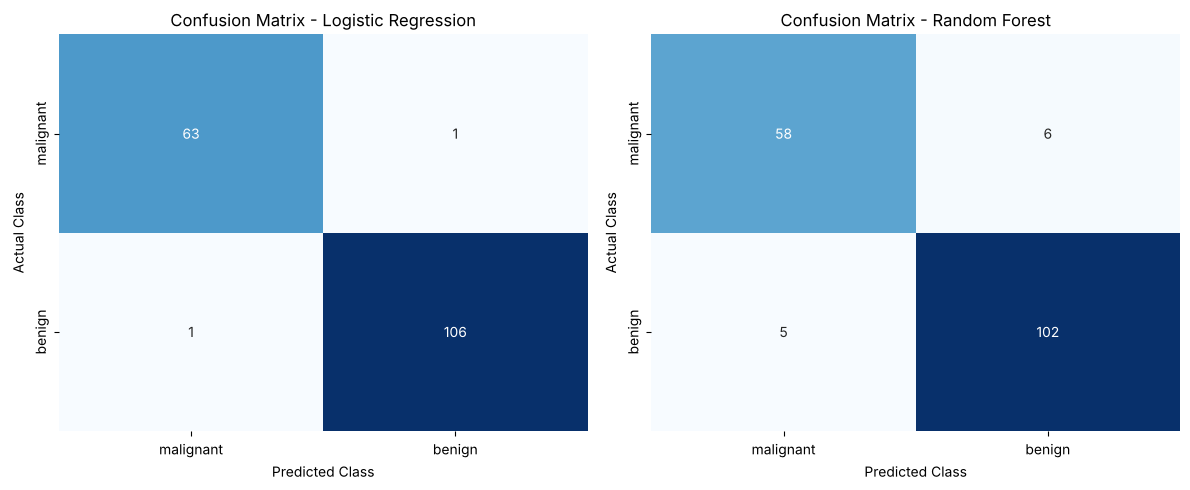

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
        xticklabels=data.target_names, yticklabels=data.target_names
    )
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    print(f"{name}: False Negative (malignant -> benign) = {cm[0, 1]}, "
          f"False Positive (benign -> malignant) = {cm[1, 0]}")

plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Pemeriksaan kekokohan: Stratified 5-fold Cross-Validation**

Hasil dari satu kali pembagian data dapat dipengaruhi oleh `random_state`. Sebagai pemeriksaan tambahan (bukan pengganti hasil utama 70:30), kedua model dievaluasi dengan cross-validation pada seluruh dataset.

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "recall_malignant": make_scorer(recall_score, pos_label=0),
    "f1_malignant": make_scorer(f1_score, pos_label=0),
}

cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X, y, cv=skf, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "Accuracy (mean)": s["test_accuracy"].mean(),
        "Accuracy (std)": s["test_accuracy"].std(),
        "Recall malignant (mean)": s["test_recall_malignant"].mean(),
        "F1 malignant (mean)": s["test_f1_malignant"].mean(),
    })

pd.DataFrame(cv_rows).set_index("Model").round(4)

,Accuracy (mean),Accuracy (std),Recall malignant (mean),F1 malignant (mean)
Model,,,,
Logistic Regression,0.9737,0.0166,0.9436,0.9633
Random Forest,0.9561,0.0123,0.9389,0.9407


# **Step 9: Analisis dan Kesimpulan**

## 9.1 Algoritma mana yang lebih baik?

*(Angka berasal dari eksekusi dengan `random_state=42`; pada versi scikit-learn yang berbeda nilai Random Forest dapat bergeser tipis.)*

| Metrik | Logistic Regression | Random Forest |
|---|---|---|
| Accuracy | 98,83% | 93,57% |
| Precision (malignant) | 0,984 | 0,921 |
| Recall (malignant) | 0,984 | 0,906 |
| F1-score (malignant) | 0,984 | 0,913 |
| ROC-AUC | 0,998 | 0,991 |
| False Negative (malignant → benign) | **1** | **6** |
| False Positive (benign → malignant) | 1 | 5 |

*   Dari 171 sampel uji, Logistic Regression hanya salah pada 2 sampel, sedangkan Random Forest salah pada 11 sampel.
*   **Logistic Regression lebih baik pada semua metrik** pada pembagian data ini. Selisih terpenting ada pada recall malignant: Random Forest melewatkan 6 dari 64 tumor ganas (≈9,4%), sedangkan Logistic Regression hanya 1 (≈1,6%).
*   Cross-validation 5-fold menunjukkan arah yang sama (accuracy ≈ 97,4% vs ≈ 95,6%), tetapi dengan selisih yang jauh lebih kecil. Jadi sebagian selisih 98,8% vs 93,6% pada satu *split* berasal dari variasi pembagian data, bukan semata perbedaan kemampuan model.
*   **Dugaan penyebab:** dataset kecil (569 sampel) dengan 30 fitur numerik yang saling berkorelasi tinggi dan kelas yang relatif mudah dipisahkan secara hampir linear cocok untuk model linear yang sudah di-*scale*. Random Forest yang lebih fleksibel tidak otomatis lebih unggul pada data kecil. Ini adalah dugaan yang konsisten dengan hasil, bukan sesuatu yang dibuktikan oleh eksperimen ini.
*   Random Forest dijalankan dengan parameter bawaan tanpa *hyperparameter tuning*, sehingga kesimpulan berlaku untuk konfigurasi ini.

## 9.2 Mengapa evaluasi tidak cukup hanya dengan accuracy?

1.   **Biaya kesalahan tidak setara.** False Negative (ganas diprediksi jinak) dapat menunda diagnosis dan pengobatan, sedangkan False Positive (jinak diprediksi ganas) umumnya berujung pemeriksaan lanjutan. Accuracy memperlakukan keduanya sama.
2.   **Accuracy menyembunyikan jenis kesalahan.** Pada eksperimen ini kedua model tampak baik (accuracy > 93%), tetapi jumlah False Negative-nya berbeda jauh (1 vs 6). Hanya Confusion Matrix dan recall yang memperlihatkannya.
3.   **Ketidakseimbangan kelas.** Dataset ini 37% malignant dan 63% benign; model yang selalu menebak "benign" sudah mencapai ≈ 62,7% accuracy tanpa mendeteksi satu pun kanker. Pada data yang lebih timpang, accuracy bisa jauh lebih menyesatkan.
4.   **Metrik pelengkap menjawab pertanyaan berbeda:** recall (berapa kanker yang terdeteksi), precision (berapa prediksi ganas yang benar), F1-score (keseimbangan keduanya), dan ROC-AUC (kemampuan membedakan kelas di berbagai threshold).
5.   **Jumlah data uji terbatas.** Dengan 171 sampel uji, selisih satu-dua kasus sudah mengubah accuracy cukup besar, sehingga Confusion Matrix dan cross-validation perlu dilihat bersama.

## 9.3 Kesimpulan

1.   Dataset dibagi **70% training (398 sampel) dan 30% testing (171 sampel)** dengan stratifikasi; pembagian yang sama dipakai untuk kedua algoritma.
2.   Pada eksperimen ini **Logistic Regression** (accuracy 98,83%, recall malignant 0,984, F1 0,984) **mengungguli Random Forest** (accuracy 93,57%, recall malignant 0,906, F1 0,913) pada seluruh metrik.
3.   Perbedaan yang paling bermakna secara klinis adalah jumlah False Negative: 1 (Logistic Regression) berbanding 6 (Random Forest).
4.   Cross-validation mendukung arah hasil yang sama dengan selisih lebih kecil. Kesimpulan berlaku untuk dataset dan konfigurasi ini, bukan klaim umum bahwa model linear selalu lebih baik.
5.   Evaluasi model klasifikasi kanker harus memakai Confusion Matrix, recall, precision, F1-score, dan ROC-AUC, bukan accuracy saja.

> Catatan: notebook ini hanya untuk pembelajaran. Hasil model tidak boleh digunakan sebagai pengganti diagnosis medis profesional.